In [ ]:
from random import *

In [ ]:
def generarGrafoAleatorio(n,m):
  g = [[] for _ in range(n)]
  for i in range(m):#para la cantidad de aristas
    v1 = randint(0,n-1)#elegir aleatoriamente el vertice 1
    v2 = randint(0,n-1)#elegir aleatoriamente el vertice 2
    #evitar repetir aristas
    while v1 == v2 or v2 in g[v1]: #si se detecta que v1==2 o v2 ya es vecino de v1
      v1 = randint(0,n-1)
      v2 = randint(0,n-1)
    g[v1] += [v2] #g[v1].append(v2) #agregar el v2 al vecindario del v1
    g[v2] += [v1] #g[v2].append(v1) #agregar el v1 al vecindario del v2
  return g

generarGrafoAleatorio(10,30)

[[2, 6, 5, 7, 4],
 [8, 2, 5, 4, 9],
 [1, 3, 5, 9, 8, 0, 7, 4, 6],
 [2, 8, 6, 7],
 [6, 8, 0, 1, 9, 2],
 [2, 8, 6, 1, 0],
 [9, 4, 5, 0, 3, 2, 7],
 [8, 2, 9, 0, 3, 6],
 [1, 3, 5, 7, 2, 4, 9],
 [6, 2, 8, 7, 4, 1]]

[[12, 6, 14, 18, 7, 17], [8, 13], [10, 12], [9, 12, 14, 5, 17, 6, 15], [19, 16], [3, 19], [11, 8, 0, 17, 3], [0, 15], [1, 13, 6, 11], [3, 10], [9, 14, 2], [6, 8], [13, 0, 3, 18, 2, 15], [18, 8, 12, 14, 1, 17], [16, 13, 0, 19, 17, 3, 10, 15], [7, 3, 14, 12], [14, 17, 4], [16, 6, 14, 0, 3, 13, 19], [13, 0, 12], [14, 4, 17, 5]]


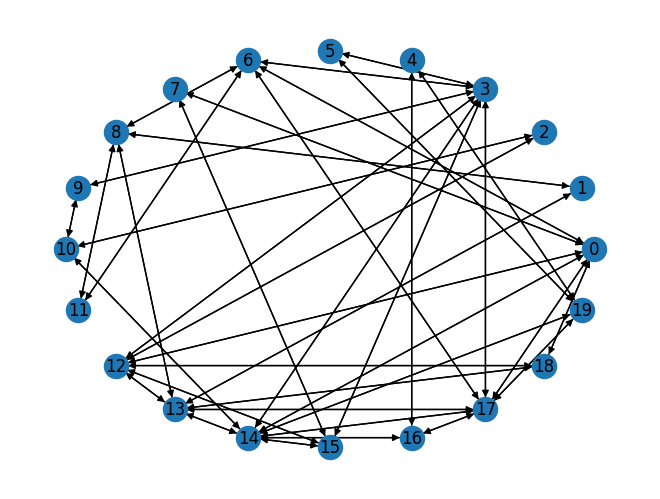

In [ ]:
import networkx as nx

n = 20
m = 40
#generar grafo como lista de listas
grafo = generarGrafoAleatorio(n,m)
print(grafo)
#crear grafo
G = nx.DiGraph()
#agregar nodos
for u in range(len(grafo)):
  G.add_node(u)
#agregar aristas
for u in range(len(grafo)):
  for v in grafo[u]:
    G.add_edge(u,v)
#plotear grafo con disposición circular
nx.draw_circular(G, with_labels=True)

In [ ]:
!pip install ortools

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 29.8/29.8 MB 23.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 137.4/137.4 kB 7.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 323.4/323.4 kB 10.6 MB/s eta 0:00:00
  Attempting uninstall: protobuf
    Found existing installation: protobuf 5.29.6
    Uninstalling protobuf-5.29.6:
      Successfully uninstalled protobuf-5.29.6
  Attempting uninstall: absl-py
    Found existing installation: absl-py 1.4.0
    Uninstalling absl-py-1.4.0:
      Successfully uninstalled absl-py-1.4.0
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-ai-generativelanguage 0.6.15 requires protobuf!=4.21.0,!=4.21.1,!=4.21.2,!=4.21.3,!=4.21.4,!=4.21.5,<6.0.0dev,>=3.20.2, but you have protobuf 6.33.6 which is incompatible.
grpcio-status 1.71.2 requires protobuf<6.0dev,>=5.26.1, but you have protobuf 6.33.6 wh

#Ejercicio 1

In [ ]:
from ortools.sat.python import cp_model

#crear CSP
model = cp_model.CpModel()
#variables y dominios
color = [model.NewIntVar(1,n,'color_nodo_'+str(i)) for i in range(n)]
print(color)
#restricciones
for u in range(len(grafo)):
  for v in grafo[u]:
    model.Add(color[u] != color[v])

[color_nodo_0(1..20), color_nodo_1(1..20), color_nodo_2(1..20), color_nodo_3(1..20), color_nodo_4(1..20), color_nodo_5(1..20), color_nodo_6(1..20), color_nodo_7(1..20), color_nodo_8(1..20), color_nodo_9(1..20), color_nodo_10(1..20), color_nodo_11(1..20), color_nodo_12(1..20), color_nodo_13(1..20), color_nodo_14(1..20), color_nodo_15(1..20), color_nodo_16(1..20), color_nodo_17(1..20), color_nodo_18(1..20), color_nodo_19(1..20)]


In [ ]:
#crear solver
solver = cp_model.CpSolver()
status = solver.Solve(model)

c = [] #lista de colores asignados a los nodos
if status == cp_model.OPTIMAL:
  for u in range(len(grafo)):
    print("Nodo",u,'de color',solver.Value(color[u]))
    c += [solver.Value(color[u])]

Nodo 0 de color 5
Nodo 1 de color 5
Nodo 2 de color 3
Nodo 3 de color 5
Nodo 4 de color 3
Nodo 5 de color 2
Nodo 6 de color 1
Nodo 7 de color 2
Nodo 8 de color 4
Nodo 9 de color 2
Nodo 10 de color 1
Nodo 11 de color 3
Nodo 12 de color 2
Nodo 13 de color 3
Nodo 14 de color 2
Nodo 15 de color 1
Nodo 16 de color 1
Nodo 17 de color 4
Nodo 18 de color 1
Nodo 19 de color 1


[(0.7099947635936268, 0.9343322470682939, 0.8039838791810766), (0.5431192452237217, 0.02029132342562634, 0.2509180421631684), (0.6039122880279986, 0.7489144564238975, 0.009303182329952198), (0.5275233723141104, 0.48143720937744394, 0.43869961608503194), (0.32029888108915594, 0.2172004594397856, 0.43022104618007595), (0.42048431156640553, 0.3318278298852073, 0.5525648226495955), (0.5148205040634188, 0.21647457586817054, 0.2504590701420105), (0.1747845749236805, 0.6165458695072523, 0.9209889501682652), (0.962172238592939, 0.6942600810274538, 0.9814890086342518), (0.8569370220227722, 0.7650444485755371, 0.35746886117972576), (0.56162203227062, 0.3128396779108795, 0.04779562222380618), (0.5376896339720642, 0.36337964295405556, 0.8633408385432518), (0.6507574644616271, 0.9836157082620163, 0.16240180973223817), (0.7350481013459299, 0.6905377985412771, 0.8284260435013799), (0.21234130468724555, 0.7251569112882552, 0.4930557157339901), (0.7607584763193342, 0.6215227002423344, 0.351059648198751

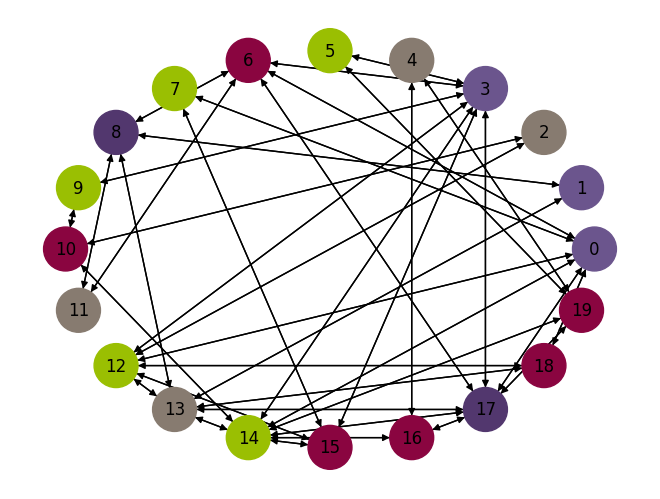

In [ ]:
colors = [(random(),random(),random()) for i in range(n)]
print(colors)

G1 = nx.DiGraph()
for u in range(len(grafo)):
  G1.add_node(u)
for u in range(len(grafo)):
  for v in grafo[u]:
    G1.add_edge(u,v)

nx.draw_circular(G1, with_labels=True, node_color=[colors[x] for x in c], node_size=1000)

[[19, 8, 17, 21, 3, 46, 30], [7, 26, 18, 49, 36, 34, 46, 8, 43, 21, 15, 33], [16, 27, 23, 30, 4, 24], [21, 36, 27, 13, 0, 15, 39], [28, 6, 45, 9, 14, 26, 2, 39, 8, 48], [45, 40, 34, 41, 28, 30, 21, 24], [4, 35, 27, 36, 16, 38], [31, 1, 34, 35, 44, 23], [9, 41, 20, 0, 27, 12, 1, 4, 43], [8, 41, 44, 4, 37, 30, 46], [27, 17, 46, 31, 12, 41, 16, 34, 33, 32], [47, 32, 31, 45, 44], [38, 14, 22, 26, 30, 15, 10, 8, 24, 31, 33, 35], [17, 19, 47, 26, 3, 42, 23, 31, 43, 29, 41], [34, 12, 38, 49, 4, 31], [49, 3, 12, 34, 1, 43], [2, 25, 45, 21, 10, 6], [37, 13, 34, 10, 0, 28, 41], [28, 1, 49, 37, 47], [0, 23, 13, 28, 30, 46, 34, 35, 31], [8, 37, 32, 41, 43, 46, 35, 25, 21], [3, 0, 42, 16, 1, 20, 5, 29], [12, 26, 27, 34], [19, 30, 2, 25, 13, 28, 31, 7], [47, 28, 12, 34, 2, 5], [34, 44, 16, 49, 23, 28, 20], [41, 13, 12, 1, 37, 22, 4, 28, 47, 32, 48], [47, 10, 3, 37, 2, 8, 48, 39, 41, 22, 6, 34, 42], [4, 18, 44, 40, 24, 19, 5, 17, 26, 25, 23, 34, 35, 38], [48, 37, 44, 13, 21, 41], [45, 12, 23, 19, 5, 

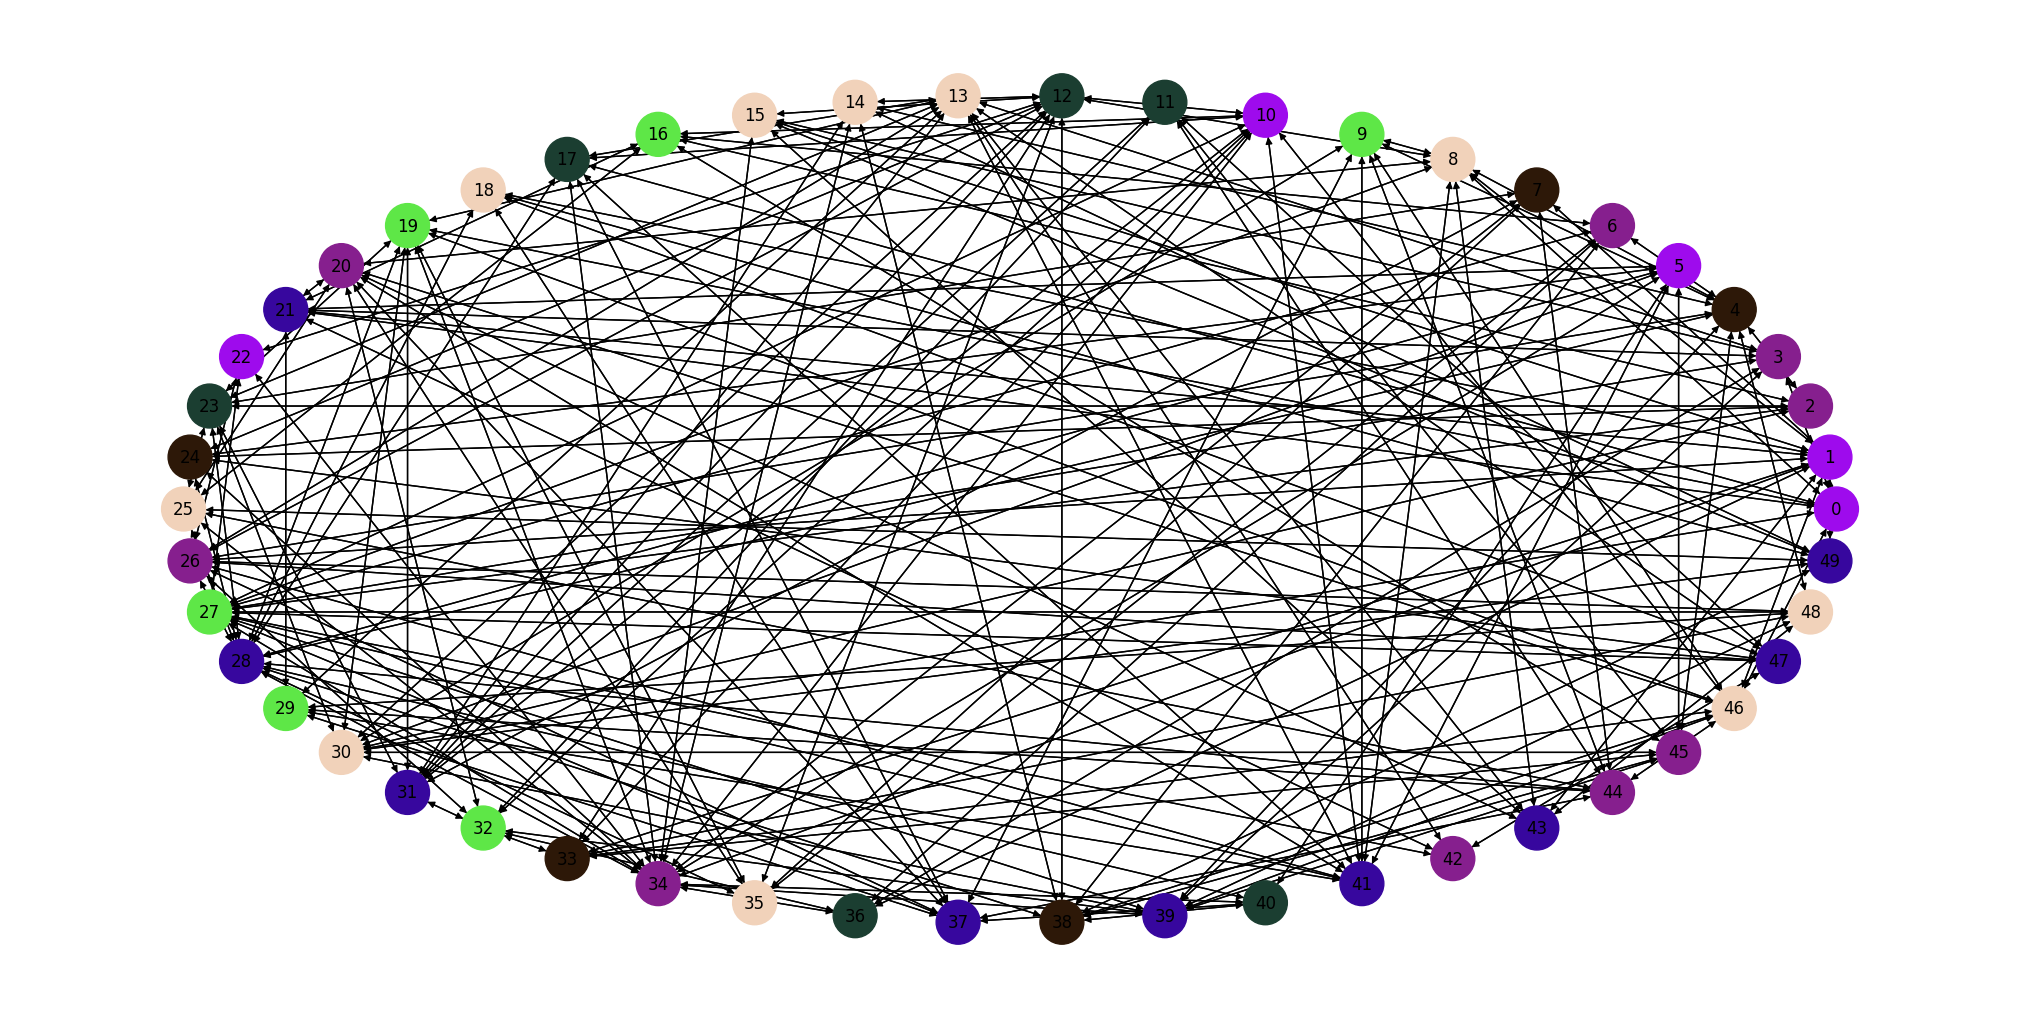

In [ ]:
import matplotlib.pyplot as plt

n = 50
m = 200
#generar grafo como lista de listas
grafo = generarGrafoAleatorio(n,m)
print(grafo)
#crear grafo
G = nx.DiGraph()
#agregar nodos
for u in range(len(grafo)):
  G.add_node(u)
#agregar aristas
for u in range(len(grafo)):
  for v in grafo[u]:
    G.add_edge(u,v)

#crear CSP
model = cp_model.CpModel()
#variables y dominios
color = [model.NewIntVar(1,n,'color_nodo_'+str(i)) for i in range(n)]
print(color)
#restricciones
for u in range(len(grafo)):
  for v in grafo[u]:
    model.Add(color[u] != color[v])
#crear solver
solver = cp_model.CpSolver()
status = solver.Solve(model)

c = [] #lista de colores asignados a los nodos
if status == cp_model.OPTIMAL:
  for u in range(len(grafo)):
    #print("Nodo",u,'de color',solver.Value(color[u]))
    c += [solver.Value(color[u])]

colors = [(random(),random(),random()) for i in range(n)]
print(colors)

G1 = nx.DiGraph()
for u in range(len(grafo)):
  G1.add_node(u)
for u in range(len(grafo)):
  for v in grafo[u]:
    G1.add_edge(u,v)

plt.figure(figsize=(20,10))
nx.draw_circular(G1, with_labels=True, node_color=[colors[x] for x in c], node_size=1000)

#Ejercicio 2

In [ ]:
from ortools.sat.python import cp_model

sumas = [20,18,14,19,2,7,8]

#crear CSP
model = cp_model.CpModel()
#variables y dominios
vecindario = []
for i in range(7):
  vecindario += [[model.new_bool_var('v_'+str(i)+'_'+str(j)) for j in range(7)]]
print(vecindario)

#restricciones
for i in range(7):
  model.Add(sum((j+1)*vecindario[i][j] for j in range(7)) == sumas[i])
  model.Add(vecindario[i][i] == 0)
  for j in range(7):
    model.Add(vecindario[i][j] == vecindario[j][i])

[[v_0_0(0..1), v_0_1(0..1), v_0_2(0..1), v_0_3(0..1), v_0_4(0..1), v_0_5(0..1), v_0_6(0..1)], [v_1_0(0..1), v_1_1(0..1), v_1_2(0..1), v_1_3(0..1), v_1_4(0..1), v_1_5(0..1), v_1_6(0..1)], [v_2_0(0..1), v_2_1(0..1), v_2_2(0..1), v_2_3(0..1), v_2_4(0..1), v_2_5(0..1), v_2_6(0..1)], [v_3_0(0..1), v_3_1(0..1), v_3_2(0..1), v_3_3(0..1), v_3_4(0..1), v_3_5(0..1), v_3_6(0..1)], [v_4_0(0..1), v_4_1(0..1), v_4_2(0..1), v_4_3(0..1), v_4_4(0..1), v_4_5(0..1), v_4_6(0..1)], [v_5_0(0..1), v_5_1(0..1), v_5_2(0..1), v_5_3(0..1), v_5_4(0..1), v_5_5(0..1), v_5_6(0..1)], [v_6_0(0..1), v_6_1(0..1), v_6_2(0..1), v_6_3(0..1), v_6_4(0..1), v_6_5(0..1), v_6_6(0..1)]]


In [ ]:
#crear solver
solver = cp_model.CpSolver()
status = solver.Solve(model)

grafo_ = []
if status == cp_model.OPTIMAL:
  for i in range(7):
    v_ = []
    for j in range(7):
      print(solver.Value(vecindario[i][j]),end=' ')
      if solver.Value(vecindario[i][j]):
        v_ += [j]
    grafo_ += [v_]
    print(sumas[i])
print("="*10)
for u in range(len(grafo_)):
  print(u+1,'\t',sumas[u],'\t',[v+1 for v in grafo_[u]], )

0 0 1 1 0 1 1 20
0 0 1 1 1 1 0 18
1 1 0 1 0 0 1 14
1 1 1 0 0 1 1 19
0 1 0 0 0 0 0 2
1 1 0 1 0 0 0 7
1 0 1 1 0 0 0 8
1 	 20 	 [3, 4, 6, 7]
2 	 18 	 [3, 4, 5, 6]
3 	 14 	 [1, 2, 4, 7]
4 	 19 	 [1, 2, 3, 6, 7]
5 	 2 	 [2]
6 	 7 	 [1, 2, 4]
7 	 8 	 [1, 3, 4]


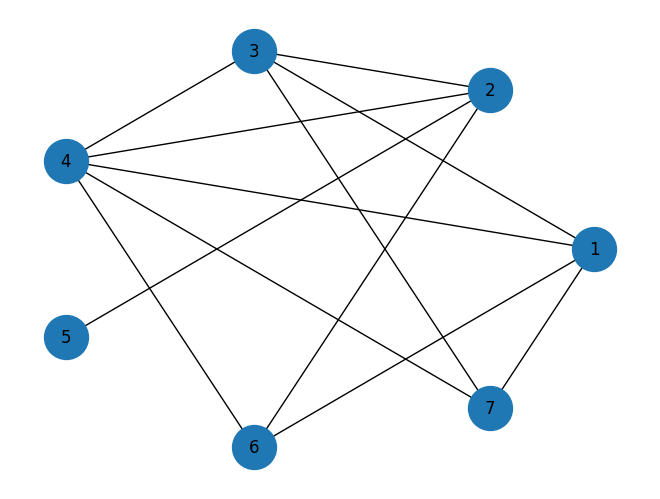

In [ ]:
G1 = nx.Graph()
for u in range(len(grafo_)):
  G1.add_node(u+1)
for u in range(len(grafo_)):
  for v in grafo_[u]:
    #print(u,v)
    G1.add_edge(u+1,v+1)

nx.draw_circular(G1, with_labels=True, node_size=1000)

#Ejercicio 3

In [ ]:
class VarArraySolutionPrinter(cp_model.CpSolverSolutionCallback):
    """Callback to capture and print solutions in real-time."""
    def __init__(self, variables):
        super().__init__()
        self.__variables = variables
        self.__solution_count = 0

    def on_solution_callback(self):
        self.__solution_count += 1
        print(f"Solution #{self.__solution_count}: ", end="\t")

        # Access variable values using self.Value()
        solution_output = [f"{v.Name()} = {self.Value(v)}" for v in self.__variables]
        print(", ".join(solution_output))

    def get_solution_count(self):
        return self.__solution_count

In [ ]:
from ortools.sat.python import cp_model

#crear CSP
model = cp_model.CpModel()
#variables y dominios
x = model.new_int_var(2,6,'x')
y = model.new_int_var(2,6,'y')
z = model.new_int_var(2,6,'z')

#restricciones
model.add(x + y <= z)
model.add(4 <= z)
model.add(z < 6)

#crear solver
solver = cp_model.CpSolver()
solution_printer = VarArraySolutionPrinter([x,y,z])
status = solver.SearchForAllSolutions(model, solution_printer)

Solution #1: 	x = 2, y = 2, z = 4
Solution #2: 	x = 2, y = 2, z = 5
Solution #3: 	x = 2, y = 3, z = 5
Solution #4: 	x = 3, y = 2, z = 5


In [ ]:
from ortools.sat.python import cp_model

#crear CSP
model = cp_model.CpModel()
#variables y dominios
a = model.new_int_var(4,6,'a')
x = model.new_int_var(2,6,'x')
y = model.new_int_var(2,6,'y')
z = model.new_int_var(2,6,'z')

#restricciones
model.add(a < z)
model.add(x + y == a)
model.add(z >= 5)

#crear solver
solver = cp_model.CpSolver()
solution_printer = VarArraySolutionPrinter([a,x,y,z])
status = solver.SearchForAllSolutions(model, solution_printer)

Solution #1: 	a = 4, x = 2, y = 2, z = 5
Solution #2: 	a = 4, x = 2, y = 2, z = 6
Solution #3: 	a = 5, x = 2, y = 3, z = 6
Solution #4: 	a = 5, x = 3, y = 2, z = 6


#Geo

In [ ]:
!pip install geopandas

In [ ]:
import geopandas as gpd
import pandas as pd
import numpy as np

In [ ]:
url_data = 'https://raw.githubusercontent.com/juaneladio/peru-geojson/master/peru_departamental_simple.geojson'

In [ ]:
region_geojson = gpd.read_file(url_data)
region_geojson.head()

In [ ]:
from matplotlib.colors import ListedColormap

#lista de 25 colores en blanco
cmap = ListedColormap(['white' for _ in range(25)],name='test')

#plotear la figura con esa lista y lineas de color negro
region_geojson.plot(figsize=(20,20),edgecolor='black',cmap=cmap)
#etiquetas de la figura
plt.xlabel('Longitud')
plt.ylabel('Latitud')
plt.show()

In [ ]:
regiones = list(region_geojson['NOMBDEP'].values)
print(regiones)

In [ ]:
grafo_regional = [[15,21,12,5],[12,9,14],[7,3,4],
                  [17,20,7,2,4,10],[11,8,10,7,2,3],[19,13,12,0],
                  [14],[24,16,20,3,2,4,11],[10,14,11,4,3],
                  [1,12,21,24,18,14,15],[14,8,4,3],[14,18,24,7,4,8],
                  [13,5,0,21,9,1],[19,5,12],[1,9,18,11,8,10,6],
                  [0,21,24,9],[24,20,7],[3,20,22],
                  [9,14,24,11],[23,13,5],[7,16,17,22,3],
                  [0,15,24,9,1,12],[17,20],[19],[15,9,18,11,7,16]]
for u in range(len(grafo_regional)):
  print(regiones[u],[regiones[v] for v in grafo_regional[u]])

In [ ]:
#crear CSP
model = cp_model.CpModel()
#variables y dominios
color = [model.NewIntVar(1,25,'color_region_'+str(i)) for i in range(25)]
#restricciones
for u in range(len(grafo_regional)):
  for v in grafo_regional[u]:
    model.Add(color[u] != color[v])

In [ ]:
#crear solver
solver = cp_model.CpSolver()
status = solver.Solve(model)

c = []
if status == cp_model.OPTIMAL:
  for u in range(len(grafo_regional)):
    print('Region',u,'(',regiones[u],')','de color',solver.Value(color[u]))
    c += [solver.Value(color[u])]

In [ ]:
#imprimir cantidad de colores
print('Hay',len(c),'regiones con colores:',c)
print('Hay',len(set(c)),'colores únicos:',set(c))
#plotear
colors_regiones = ['','cyan','green','yellow','black',
                   'blue','gold','lightgray','red',
                   'pink','darkorange','violet','white',
                   'royalblue','maroon','lightseagreen']

cmap = ListedColormap([colors_regiones[c[i]] for i in range(25)],name='regions')
region_geojson.plot(figsize=(20,20),edgecolor='black',cmap=cmap)
plt.xlabel('Longitud')
plt.ylabel('Latitud')
plt.show()

In [ ]:
#crear CSP
model = cp_model.CpModel()
#variables y dominios
#color = [model.NewIntVar(1,25,'color_region_'+str(i)) for i in range(25)]

nc = []
for i in range(25):
  fila = []
  for j in range(25):
    fila += [model.NewBoolVar('color_'+str(i)+'_'+str(j))]
  nc += [fila]
print(nc)

usocolor = []
for j in range(25):
  usocolor += [model.NewBoolVar('usocolor'+str(j))]
  col = [nc[i][j] for i in range(25)]
  model.Add(sum(col) > 0).OnlyEnforceIf(usocolor[j])
  model.Add(sum(col) == 0).OnlyEnforceIf(usocolor[j].Not())

numerocolores = model.NewIntVar(1,25,'numerocolores')
model.Add(sum(usocolor) == numerocolores)

color = []
for i in range(25):
  color += [model.NewIntVar(1,25,'color_region_'+str(i))]
  for j in range(25):
    model.Add(color[i] == j+1).OnlyEnforceIf(nc[i][j])
    model.Add(color[i] != j+1).OnlyEnforceIf(nc[i][j].Not())

#restricciones
for u in range(len(grafo_regional)):
  for v in grafo_regional[u]:
    model.Add(color[u] != color[v])

#función objetivo
model.Minimize(numerocolores)

In [ ]:
#crear solver
solver = cp_model.CpSolver()
status = solver.Solve(model)

c = []
if status == cp_model.OPTIMAL:
  print("El número de colores es",solver.Value(numerocolores))
  for i in range(len(grafo_regional)):
    for j in range(len(grafo_regional)):
      print(solver.Value(nc[i][j]),end=' ')
    print()
  print()
  for i in range(len(grafo_regional)):
    print(solver.Value(usocolor[i]),end=' ')
  print()
  for u in range(len(grafo_regional)):
    print('Region',u,'(',regiones[u],')','de color',solver.Value(color[u]))
    c += [solver.Value(color[u])]

In [ ]:
#imprimir cantidad de colores
print('Hay',len(c),'regiones con colores:',c)
print('Hay',len(set(c)),'colores únicos:',set(c))
#plotear
colors_regiones = ['','cyan','green','yellow','black',
                   'blue','gold','lightgray','red',
                   'pink','darkorange','violet','white',
                   'royalblue','maroon','lightseagreen',
                   'royalblue','violet','lightseagreen',
                   'royalblue','white','lightseagreen']

cmap = ListedColormap([colors_regiones[c[i]] for i in range(25)],name='regions')
region_geojson.plot(figsize=(20,20),edgecolor='black',cmap=cmap)
plt.xlabel('Longitud')
plt.ylabel('Latitud')
plt.show()